In [1]:
%pip install -q landingai pillow matplotlib gTTS

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install landingai

In [3]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 10.4.0
JPEG encoding successful: 633 bytes


In [4]:

import os
from getpass import getpass
from landingai.predict import Predictor

API_KEY = getpass("Enter your LandingAI API Key: ")

ENDPOINT_ID = "5b2cfd6f-f6be-41a1-b5cc-7a22cf8c2a83"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully.")

Enter your LandingAI API Key:  ········


LandingAI predictor initialized successfully.


In [5]:
!pip install pillow numpy ipywidgets

In [6]:
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

file_paths = filedialog.askopenfilenames(
    title="Select Medicine Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(file_paths))

Total images selected: 13



Filename: IMG20210831191437.jpg
Image size: (9280, 6944)
Image array shape: (6944, 9280, 3)



Filename: IMG_20210831_154207.jpg
Image size: (5632, 4224)
Image array shape: (4224, 5632, 3)


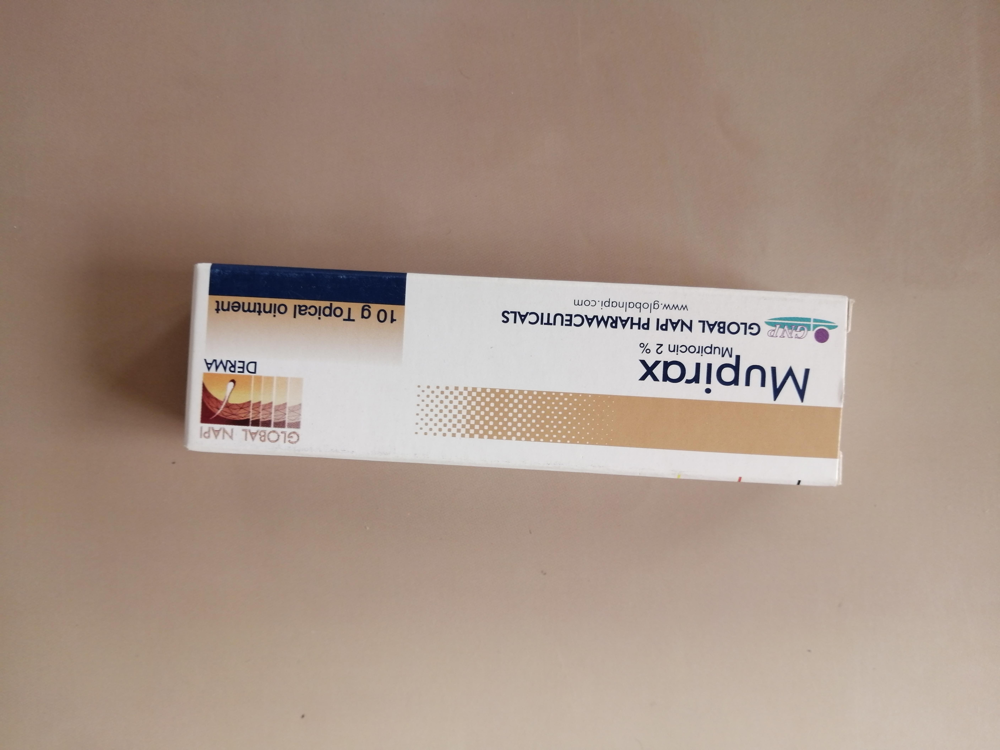


Filename: IMG_20210831_144844.jpg
Image size: (3264, 2448)
Image array shape: (2448, 3264, 3)


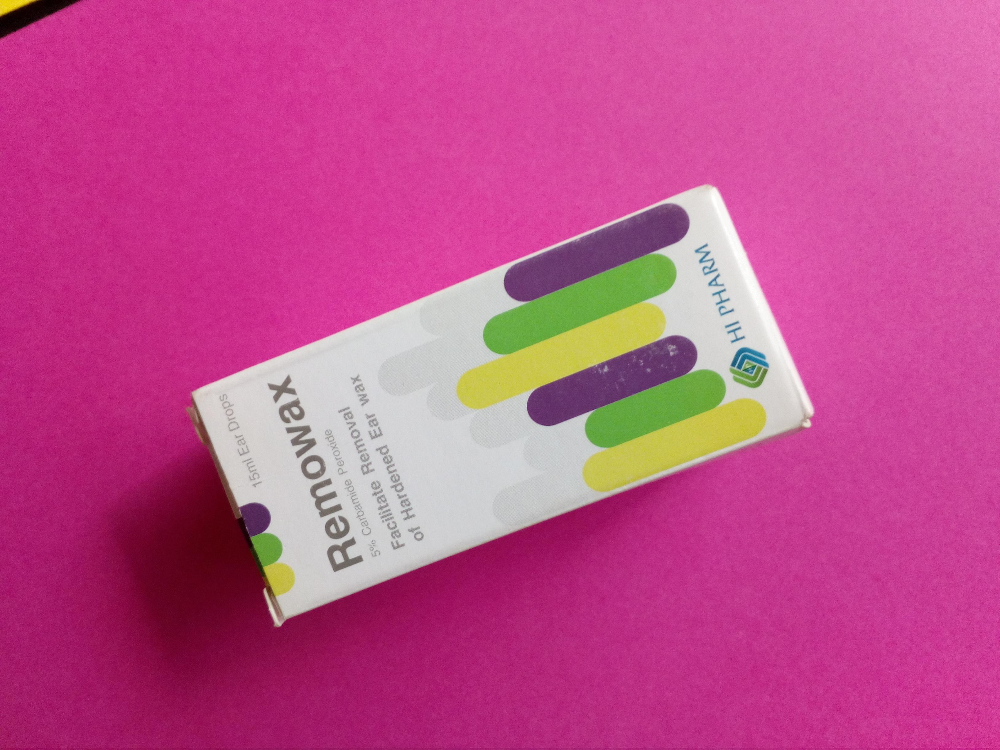


Filename: 20210831_171046.jpg
Image size: (4032, 1860)
Image array shape: (1860, 4032, 3)


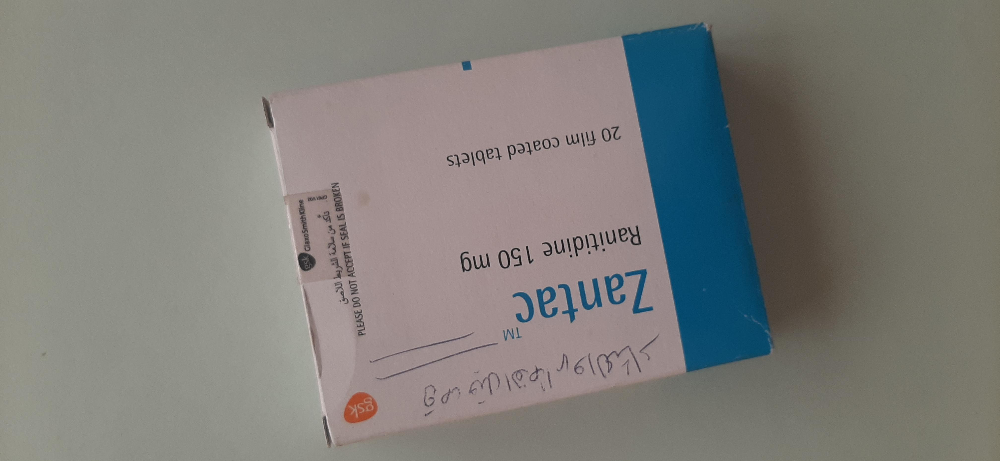


Filename: 20210831_171016.jpg
Image size: (4032, 1860)
Image array shape: (1860, 4032, 3)


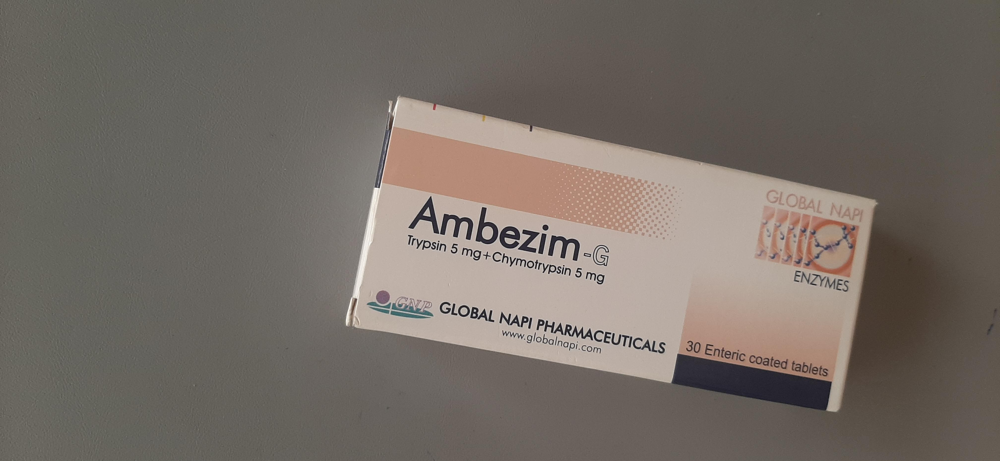


Filename: 20210831_133448.jpg
Image size: (4032, 1860)
Image array shape: (1860, 4032, 3)


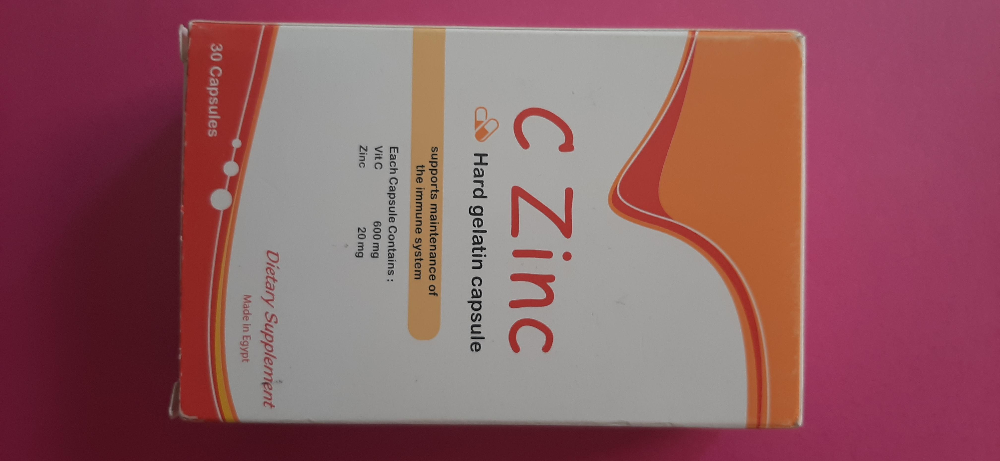


Filename: 20210831_133302.jpg
Image size: (4608, 3456)
Image array shape: (3456, 4608, 3)


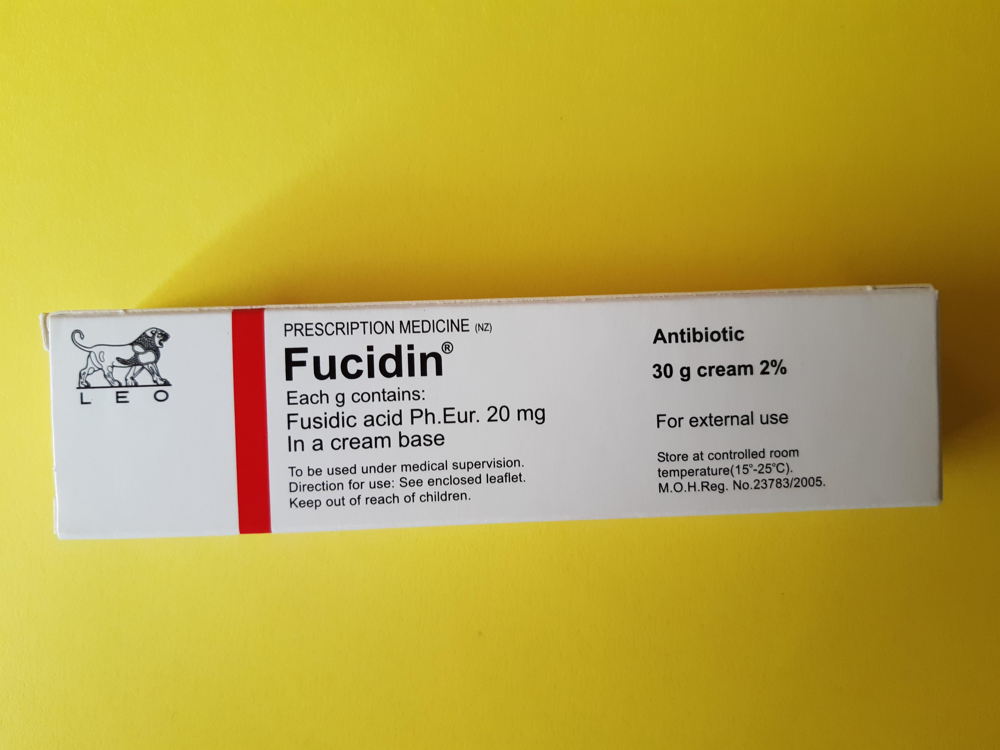


Filename: 20210831_132304.jpg
Image size: (4608, 3456)
Image array shape: (3456, 4608, 3)


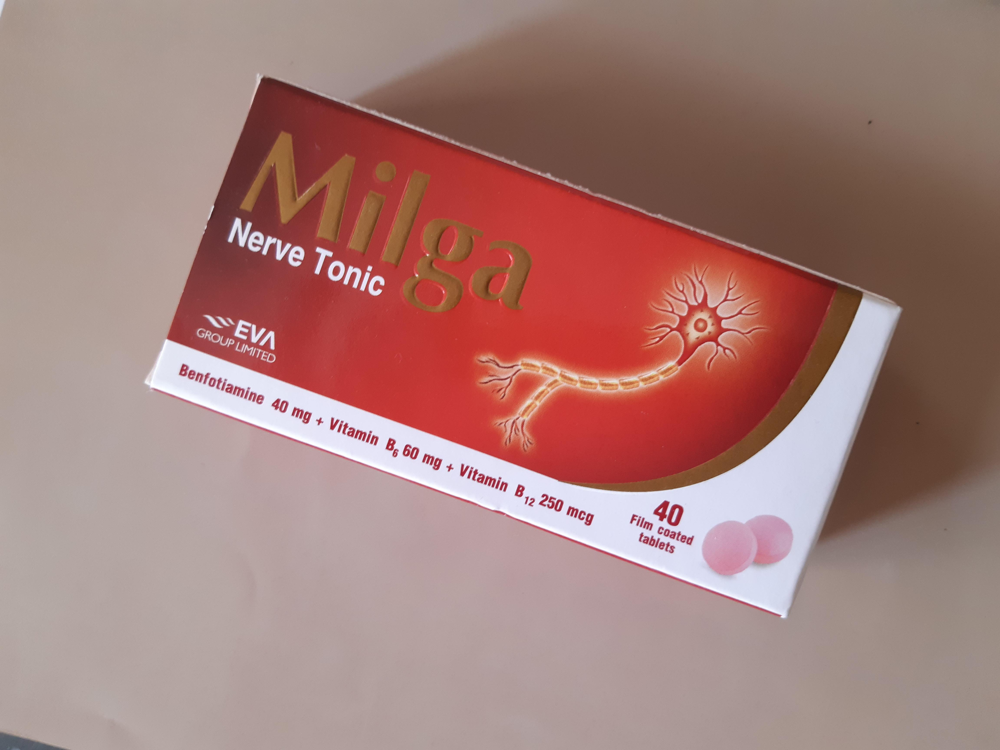


Filename: 20210831_132301.jpg
Image size: (4608, 3456)
Image array shape: (3456, 4608, 3)


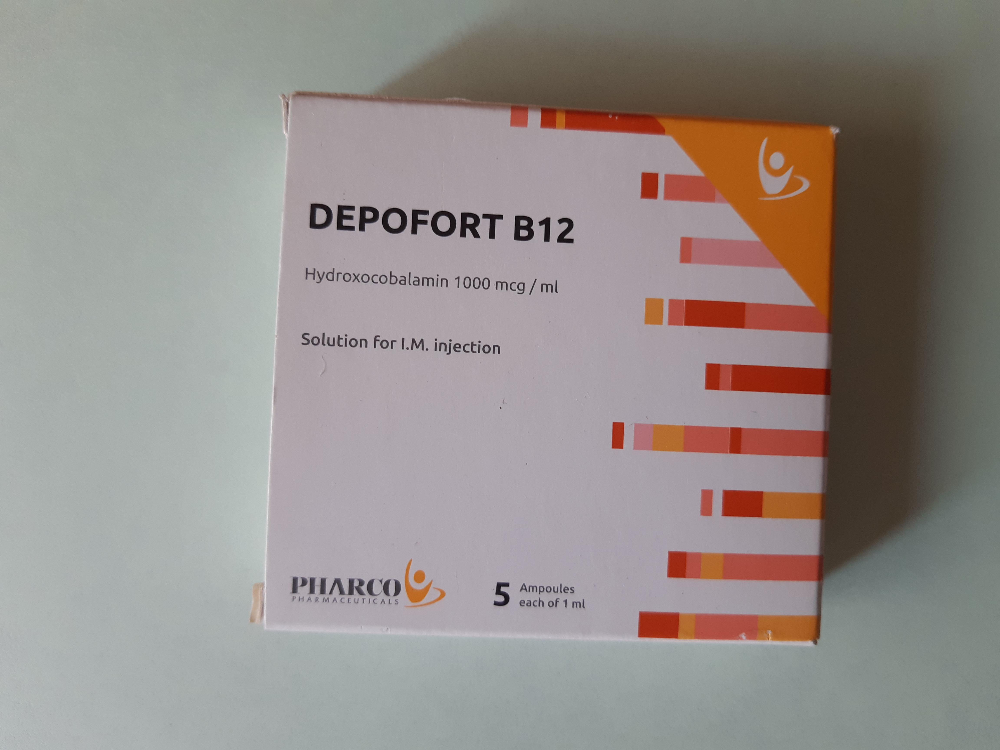


Filename: 20210831_130531.jpg
Image size: (4608, 3456)
Image array shape: (3456, 4608, 3)


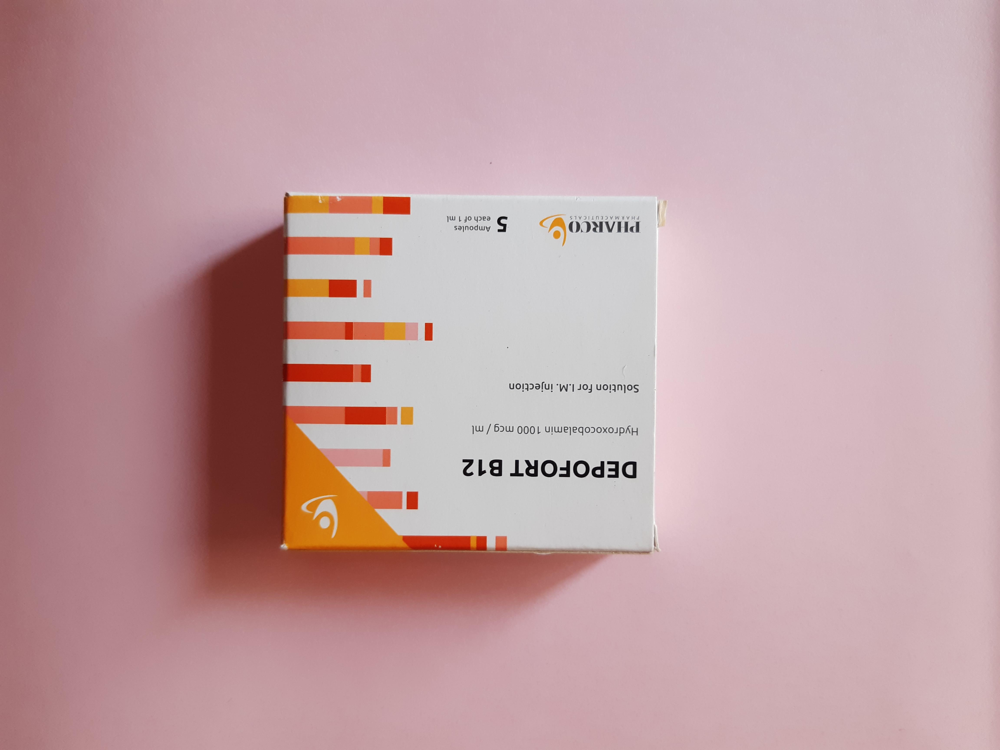


Filename: 20210831_130450.jpg
Image size: (4032, 1860)
Image array shape: (1860, 4032, 3)


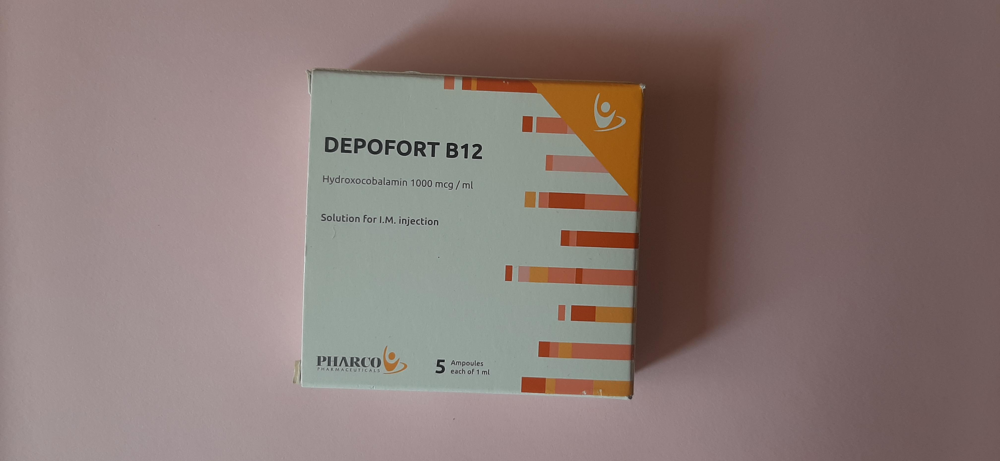


Filename: 20210831_123309.jpg
Image size: (4032, 1860)
Image array shape: (1860, 4032, 3)


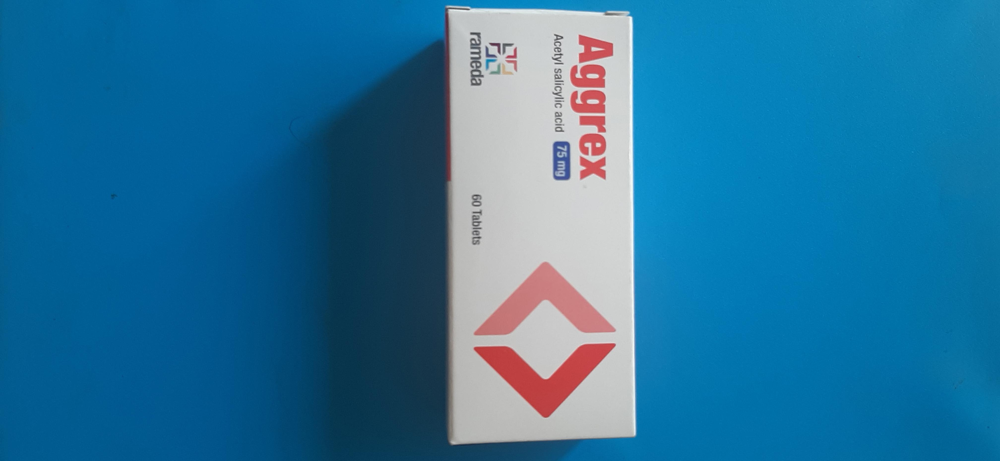


Filename: 20210831_123251.jpg
Image size: (1860, 4032)
Image array shape: (4032, 1860, 3)


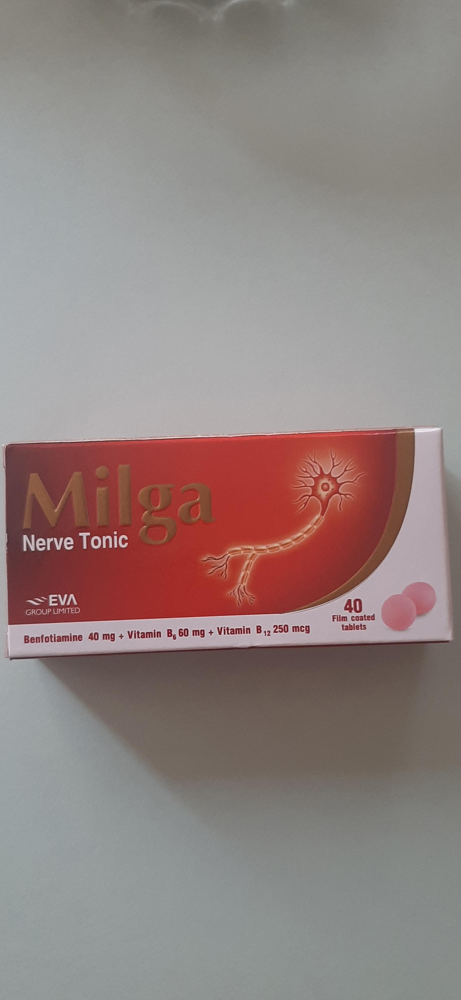


Total images processed: 13


In [7]:
images = {}

for path in file_paths:

    filename = path.split("/")[-1]

    image = Image.open(path).convert("RGB")

    image_array = np.array(image)

    images[filename] = {
        "image": image,
        "array": image_array
    }

    print("\nFilename:", filename)
    print("Image size:", image.size)
    print("Image array shape:", image_array.shape)

    display(image)

print("\nTotal images processed:", len(images))

In [8]:
all_predictions = {}

for filename, data in images.items():

    image_array = data["array"]

    predictions = predictor.predict(image_array)

    all_predictions[filename] = predictions

    print("\n" + "="*50)
    print("Image:", filename)
    print("Prediction count:", len(predictions))

    for i, prediction in enumerate(predictions, start=1):
        print(f"\nPrediction {i}:")
        print(prediction)

print("\nPredictions completed for all images!")


Image: IMG20210831191437.jpg
Prediction count: 1

Prediction 1:
score=0.5337538719177246 label_name='Betadine' label_index=2 id='3de618ac-b3af-4b1b-832a-75f10a24edc8' bboxes=(6659, 2282, 7859, 4868)

Image: IMG_20210831_154207.jpg
Prediction count: 1

Prediction 1:
score=0.8728625774383545 label_name='Mupirax' label_index=5 id='d085b21d-6c4b-4f43-841e-6b57ea5019fb' bboxes=(3460, 1908, 4669, 2233)

Image: IMG_20210831_144844.jpg
Prediction count: 2

Prediction 1:
score=0.6192123889923096 label_name='Remowax' label_index=1 id='44d3c569-ad32-4b53-9788-813bca6339e7' bboxes=(826, 1222, 1410, 1869)

Prediction 2:
score=0.4901800751686096 label_name='Zantac' label_index=6 id='4f87c2c0-8426-4982-a45c-76637fd1de2d' bboxes=(849, 1238, 1385, 1909)

Image: 20210831_171046.jpg
Prediction count: 0

Image: 20210831_171016.jpg
Prediction count: 0

Image: 20210831_133448.jpg
Prediction count: 1

Prediction 1:
score=0.6657947301864624 label_name='C Zinc' label_index=10 id='56659923-2bc2-4212-a029-76bf5

In [9]:
!pip install pillow numpy gtts ipython landingai

Medicine Label Cognitive Assistant
Upload medicine bottle images for analysis.

Analyzing: IMG_20210831_144844.jpg


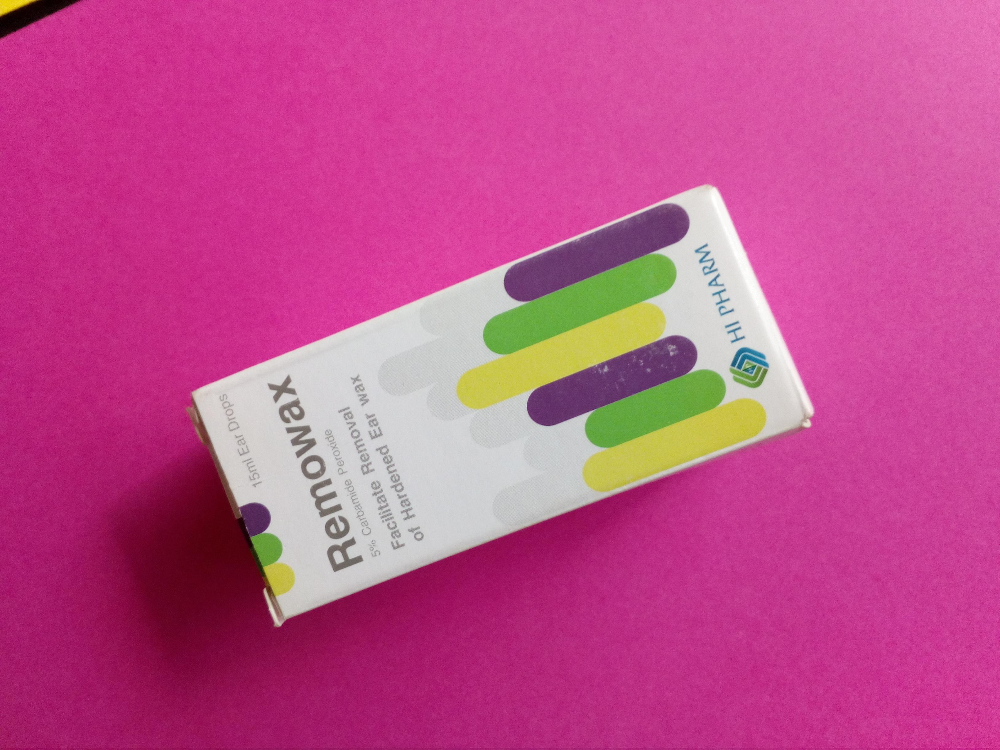


Raw model predictions:
[ObjectDetectionPrediction(score=0.6192123889923096, label_name='Remowax', label_index=1, id='d4706d0d-5256-4efd-8b8a-a8f56ad4bcc6', bboxes=(826, 1222, 1410, 1869)), ObjectDetectionPrediction(score=0.4901800751686096, label_name='Zantac', label_index=6, id='649116ec-03ed-4136-b7a2-3562e67056ed', bboxes=(849, 1238, 1385, 1909))]

Detection Results:

Prediction 1:
score=0.6192123889923096 label_name='Remowax' label_index=1 id='d4706d0d-5256-4efd-8b8a-a8f56ad4bcc6' bboxes=(826, 1222, 1410, 1869)

Prediction 2:
score=0.4901800751686096 label_name='Zantac' label_index=6 id='649116ec-03ed-4136-b7a2-3562e67056ed' bboxes=(849, 1238, 1385, 1909)


### Medicine Assistant Response
**Image:** IMG_20210831_144844.jpg

**Status:** Medicine label analysis completed.


Medicine analysis completed for all uploaded images!


In [10]:
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io
import os

def medicine_assistant():

    print("Medicine Label Cognitive Assistant")
    print("Upload medicine bottle images for analysis.")

 

    root = Tk()
    root.withdraw()
    root.attributes('-topmost', True)

    file_paths = filedialog.askopenfilenames(
        title="Select Medicine Images",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp")
        ]
    )

    root.destroy()

    if not file_paths:
        print("No images uploaded.")
        return

   
    for path in file_paths:

        filename = os.path.basename(path)

        print("\n" + "="*50)
        print("Analyzing:", filename)

        image = Image.open(path).convert("RGB")

        display(image)

        image_array = np.array(image)

     

        try:
            predictions = predictor.predict(image_array)

        except Exception as e:
            print("Prediction failed:", e)
            continue

        print("\nRaw model predictions:")
        print(predictions)

        if not predictions:
            print("No predictions returned by the model.")
            continue

   

        result = "Medicine label analysis completed."

        print("\nDetection Results:")

        for i, prediction in enumerate(predictions, start=1):

            print(f"\nPrediction {i}:")
            print(prediction)
   
 

        display(Markdown(
            f"### Medicine Assistant Response\n"
            f"**Image:** {filename}\n\n"
            f"**Status:** {result}"
        ))

     

        speech = gTTS(
            text=f"Medicine image analysis completed for {filename}. "
                 "Please review the displayed detection results.",
            lang="en"
        )

        audio_filename = "medicine_response.mp3"

        speech.save(audio_filename)

        display(Audio(audio_filename, autoplay=False))

    print("\nMedicine analysis completed for all uploaded images!")


medicine_assistant()

In [11]:

import os
from getpass import getpass
from landingai.predict import Predictor

API_KEY = getpass("Enter your LandingAI API Key: ")

ENDPOINT_ID = "870c4539-72fb-4223-bf5b-b64c5d593cad"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully.")

Enter your LandingAI API Key:  ········


LandingAI predictor initialized successfully.


In [12]:
from tkinter import Tk, filedialog
from PIL import Image
import numpy as np

root = Tk()
root.withdraw()
root.attributes('-topmost', True)

file_path = filedialog.askopenfilenames(
    title="Select Expression Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(file_path))

Total images selected: 11



Filename: Screenshot 2026-11-11 163355.png
Image size: (520, 646)
Image array shape: (646, 520, 3)


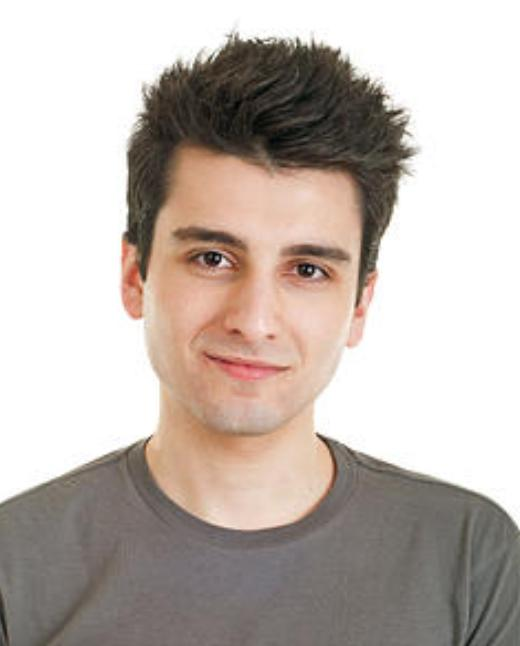


Filename: Screenshot 2026-11-11 163402.png
Image size: (535, 636)
Image array shape: (636, 535, 3)


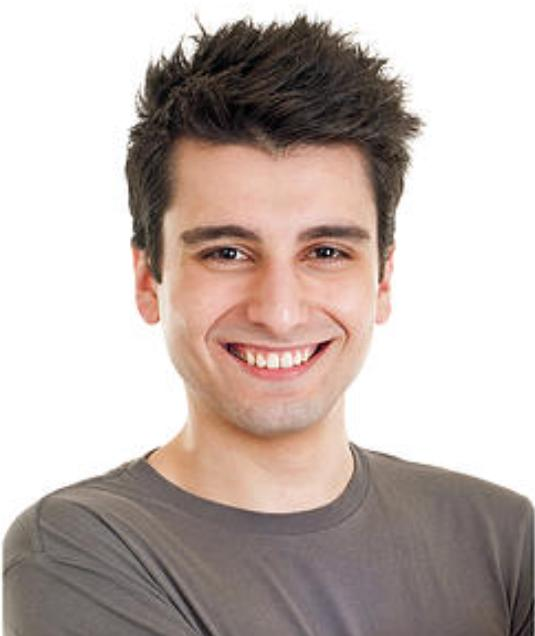


Filename: Screenshot 2026-11-11 163411.png
Image size: (517, 634)
Image array shape: (634, 517, 3)


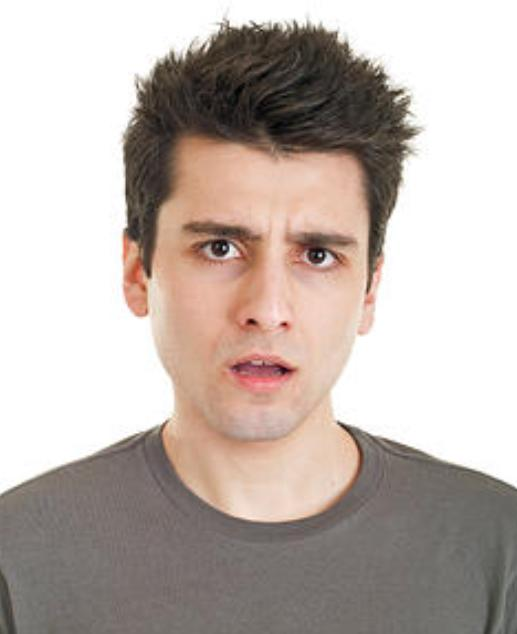


Filename: Screenshot 2026-11-11 163421.png
Image size: (517, 634)
Image array shape: (634, 517, 3)


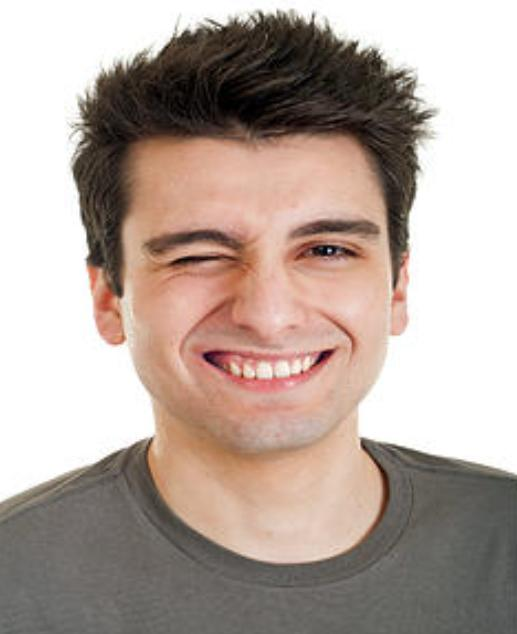


Filename: Screenshot 2026-11-11 163430.png
Image size: (516, 634)
Image array shape: (634, 516, 3)


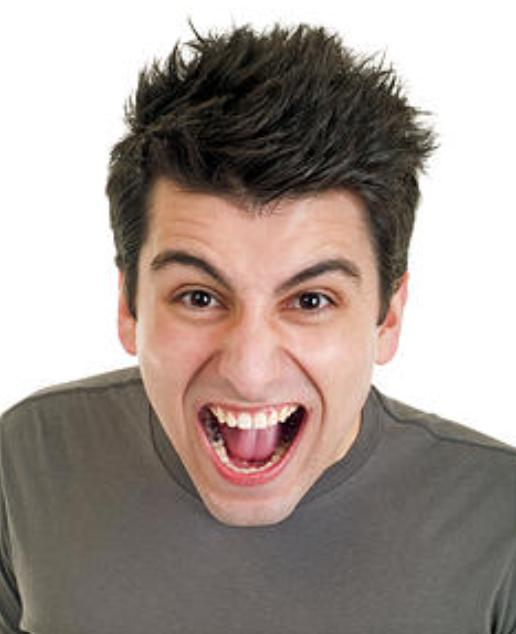


Filename: Screenshot 2026-11-11 163436.png
Image size: (511, 634)
Image array shape: (634, 511, 3)


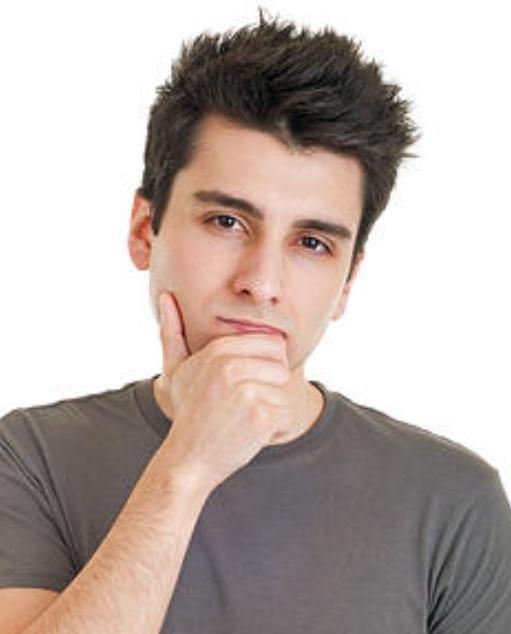


Filename: Screenshot 2026-11-11 163444.png
Image size: (457, 639)
Image array shape: (639, 457, 3)


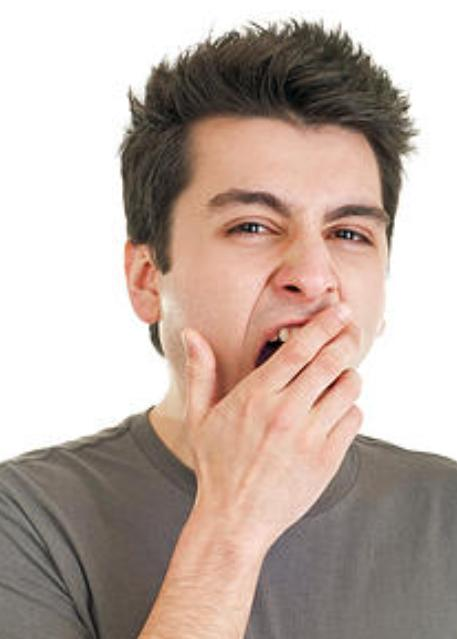


Filename: Screenshot 2026-11-11 163517.png
Image size: (631, 832)
Image array shape: (832, 631, 3)


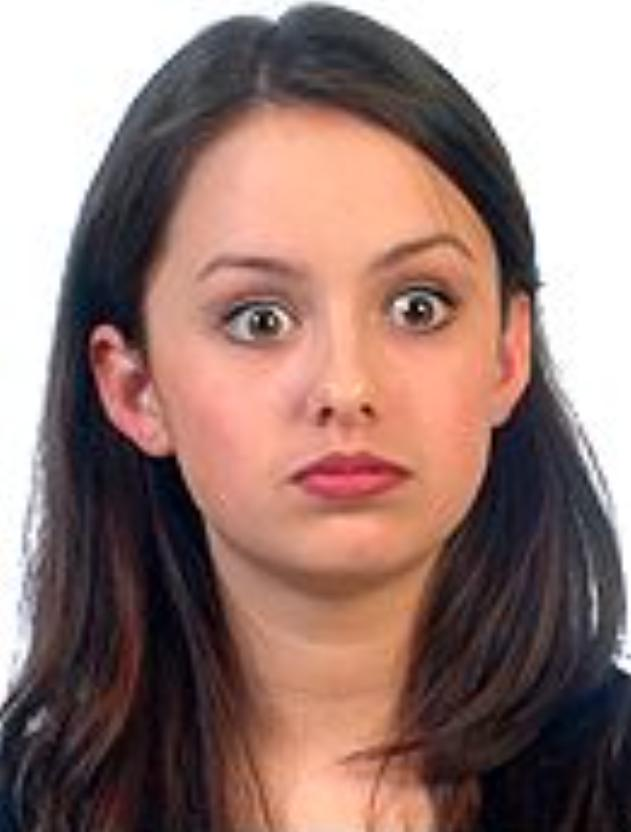


Filename: Screenshot 2026-11-11 163531.png
Image size: (616, 819)
Image array shape: (819, 616, 3)


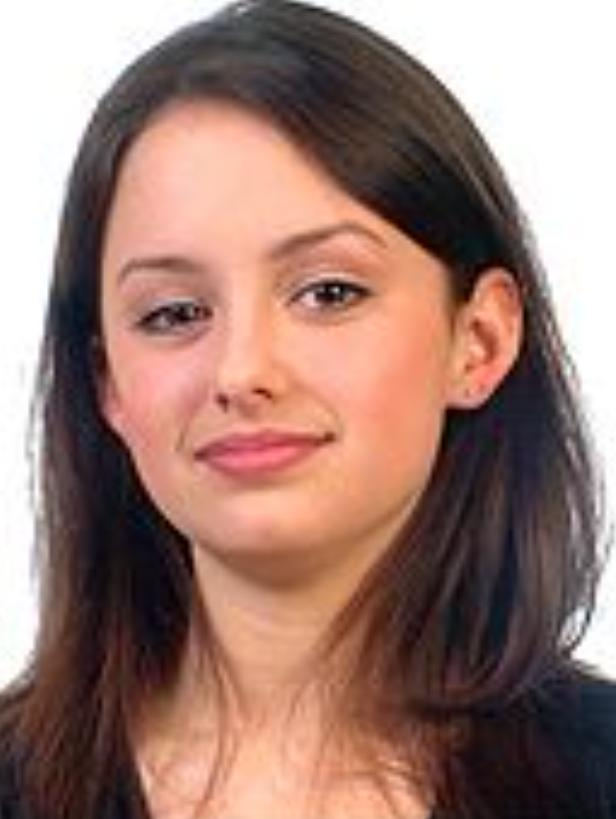


Filename: Screenshot 2026-11-11 163607.png
Image size: (594, 619)
Image array shape: (619, 594, 3)


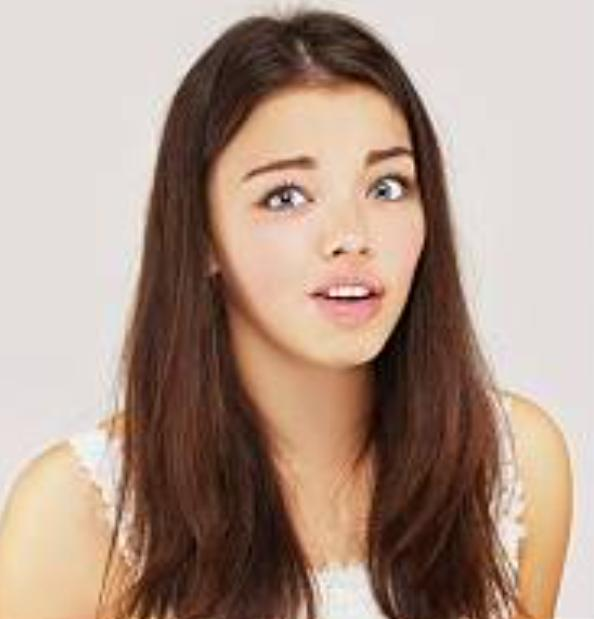


Filename: Screenshot 2026-11-11 163615.png
Image size: (622, 630)
Image array shape: (630, 622, 3)


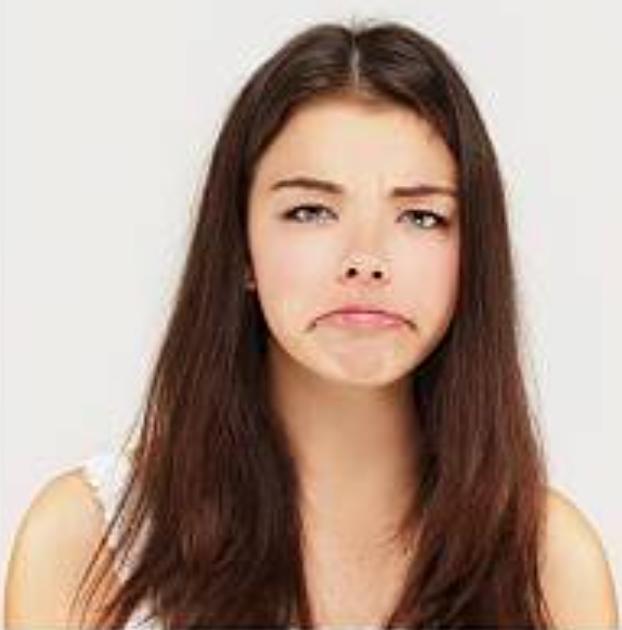


Total images processed: 11


In [13]:
image = {}

for path in file_path:

    file = path.split("/")[-1]

    im = Image.open(path).convert("RGB")

    im_array = np.array(im)

    image[file] = {
        "image": im,
        "array": im_array
    }

    print("\nFilename:", file)
    print("Image size:", im.size)
    print("Image array shape:", im_array.shape)

    display(im)

print("\nTotal images processed:", len(image))

In [14]:
all_prediction = {}

for filename, data in image.items():

    im_array = data["array"]

    prediction = predictor.predict(im_array)

    all_prediction[filename] = prediction

    print("\n" + "="*50)
    print("Image:", filename)
    print("Prediction count:", len(prediction))

    for i, prediction in enumerate(prediction, start=1):
        print(f"\nPrediction {i}:")
        print(prediction)

print("\nPredictions completed for all images!")


Image: Screenshot 2026-11-11 163355.png
Prediction count: 2

Prediction 1:
score=0.38662874698638916 label_name='smile' label_index=7 id='9e595806-03f7-4428-b1e2-57ea84dd326a' bboxes=(121, 124, 376, 438)

Prediction 2:
score=0.37627777457237244 label_name='confused' label_index=2 id='12fb7b28-c2dc-402f-b92d-0ccf8b69111a' bboxes=(121, 124, 376, 438)

Image: Screenshot 2026-11-11 163402.png
Prediction count: 0

Image: Screenshot 2026-11-11 163411.png
Prediction count: 0

Image: Screenshot 2026-11-11 163421.png
Prediction count: 0

Image: Screenshot 2026-11-11 163430.png
Prediction count: 1

Prediction 1:
score=0.3724501132965088 label_name='smile' label_index=7 id='35b08375-0e1a-44bf-b5bd-7722ceef1c9f' bboxes=(116, 160, 397, 517)

Image: Screenshot 2026-11-11 163436.png
Prediction count: 1

Prediction 1:
score=0.3781183660030365 label_name='bored' label_index=8 id='d6e7a970-0719-447c-9e3f-4f07819301ea' bboxes=(112, 65, 403, 411)

Image: Screenshot 2026-11-11 163444.png
Prediction count:

Facial Expressions Cognitive Assistant
Upload facial expression images for analysis.

Analyzing: Screenshot 2026-11-11 163607.png


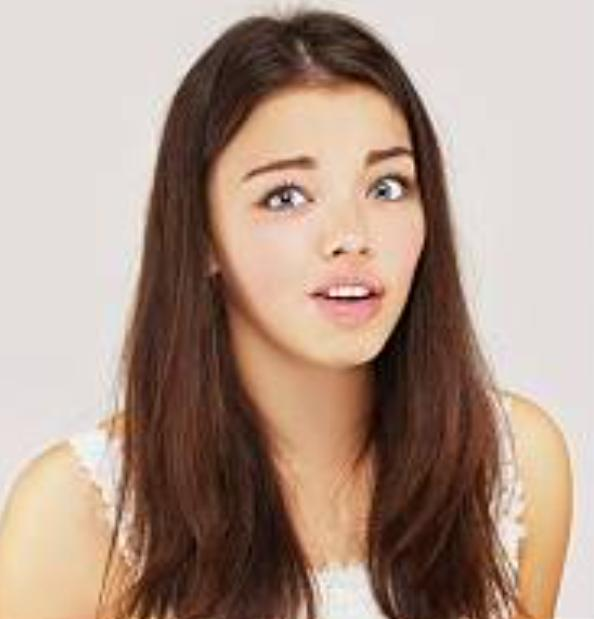


Raw model predictions:
[ObjectDetectionPrediction(score=0.42220941185951233, label_name='confused', label_index=2, id='6868e527-b93f-4958-be04-83578c79f30a', bboxes=(202, 95, 454, 376))]

Detection Results:

Prediction 1:
score=0.42220941185951233 label_name='confused' label_index=2 id='6868e527-b93f-4958-be04-83578c79f30a' bboxes=(202, 95, 454, 376)


### Facial Expressions Response
**Image:** Screenshot 2026-11-11 163607.png

**Status:** Facial Expression analysis completed.


Facial Expressions analysis completed for all uploaded images!


In [15]:
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io
import os

def expression_assistant():

    print("Facial Expressions Cognitive Assistant")
    print("Upload facial expression images for analysis.")

 

    root = Tk()
    root.withdraw()
    root.attributes('-topmost', True)

    file_path = filedialog.askopenfilenames(
        title="Select Expression Images",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp")
        ]
    )

    root.destroy()

    if not file_path:
        print("No images uploaded.")
        return

   
    for path in file_path:

        file = os.path.basename(path)

        print("\n" + "="*50)
        print("Analyzing:", file)

        im = Image.open(path).convert("RGB")

        display(im)

        im_array = np.array(im)

     

        try:
            prediction = predictor.predict(im_array)

        except Exception as e:
            print("Prediction failed:", e)
            continue

        print("\nRaw model predictions:")
        print(prediction)

        if not prediction:
            print("No predictions returned by the model.")
            continue

   

        result = "Facial Expression analysis completed."

        print("\nDetection Results:")

        for i, pred in enumerate(prediction, start=1):

            print(f"\nPrediction {i}:")
            print(pred)
   
 

        display(Markdown(
            f"### Facial Expressions Response\n"
            f"**Image:** {file}\n\n"
            f"**Status:** {result}"
        ))

     

        speech = gTTS(
            text=f"Facial Expressions image analysis completed for {file}. "
                 "Please review the displayed detection results.",
            lang="en"
        )

        audio_filename = "expression_response.mp3"

        speech.save(audio_filename)

        display(Audio(audio_filename, autoplay=False))

    print("\nFacial Expressions analysis completed for all uploaded images!")


expression_assistant()